# ZenRoom · Aviso anticipado de calor en una sala

Red pequeña que, con lo que mide el dispositivo de la sala, estima la probabilidad de que la temperatura pase el límite de la sala en los próximos 15 minutos. Mismo flujo que la Aplicación 4: se entrena aquí, se exportan los pesos a un `.h` y el ESP32 hace la inferencia en C++.

***Versión de TensorFlow:***

In [1]:
import tensorflow as tf
print(tf.__version__)

2.17.1


***Importar paquetes necesarios:***

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers

***Configuraciones:***

In [3]:
CSV = 'zenroom_minutos.csv'      # datos por minuto (generar_datos.py, fisica del simulador del Edge)
HORIZONTE = 15                  # minutos hacia adelante
VENTANA = 10                    # minutos de historia que guarda el dispositivo
LIMITES = [24.0, 24.5, 25.0]    # limites de temperatura de sala con los que se entrena
val_ratio, test_ratio = 0.2, 0.2
FEATURES = ['temp_menos_limite', 'subida_10min', 'humedad', 'ocupacion_10min', 'ruido_10min']
tf.keras.utils.set_random_seed(1234)

***Cargar los datos:*** en Colab, subir `zenroom_minutos.csv` al panel de archivos.

In [4]:
df = pd.read_csv(CSV)
print(df.shape)
df.head()

(120960, 8)


,sala,minuto,hora,dia_semana,temp_c,rh_pct,ocupada,ruido_db
0,sala-01,0,0.000,0,21.480,57.90,0,36.54
1,sala-01,1,0.017,0,21.424,57.69,0,36.33
2,sala-01,2,0.033,0,21.404,57.51,0,36.64
3,sala-01,3,0.050,0,21.380,57.23,0,36.42
4,sala-01,4,0.067,0,21.351,56.98,0,36.79


***Ver un día de una sala:*** la temperatura sube cuando hay gente y baja cuando se va.

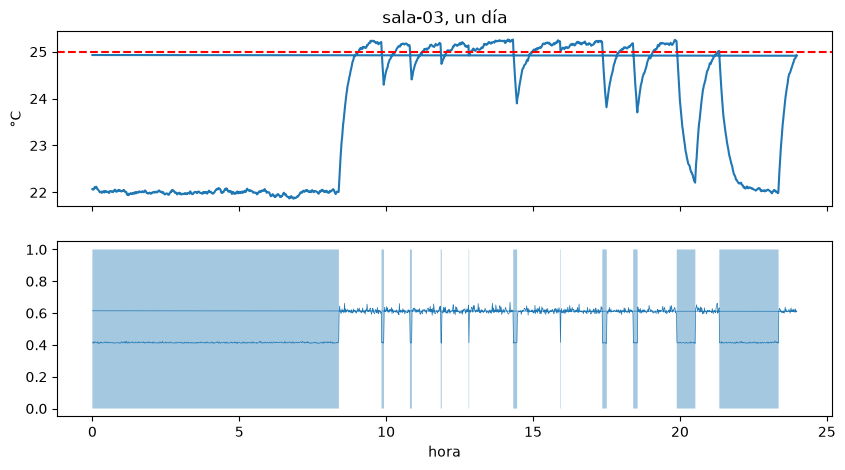

In [5]:
d = df[(df.sala == 'sala-03') & (df.minuto.between(1440, 2880))]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(d.hora, d.temp_c); ax[0].axhline(25, color='r', ls='--'); ax[0].set_ylabel('°C')
ax[1].fill_between(d.hora, d.ocupada, step='mid', alpha=.4); ax[1].plot(d.hora, d.ruido_db / 100, lw=.5)
ax[1].set_xlabel('hora'); ax[0].set_title('sala-03, un día'); plt.show()

***Construir entradas y etiqueta:*** una muestra por minuto en que la sala está ocupada y todavía por debajo del límite. La etiqueta es 1 si en los próximos 15 minutos llega al límite. No hay que etiquetar a mano: el futuro de la serie es la respuesta.

In [6]:
def leq(x):
    return 10 * np.log10(np.mean(10 ** (np.asarray(x) / 10)))   # los dB se promedian en energia

partes = {'train': [], 'val': [], 'test': []}
for sala, g in df.groupby('sala'):
    g = g.sort_values('minuto').reset_index(drop=True)
    t = g.temp_c
    futuro = t[::-1].rolling(HORIZONTE, min_periods=HORIZONTE).max()[::-1].shift(-1)
    base = pd.DataFrame({
        'sala': sala, 'minuto': g.minuto, 'temp': t, 'subida_10min': t - t.shift(VENTANA), 'humedad': g.rh_pct,
        'ocupacion_10min': g.ocupada.rolling(VENTANA).mean(), 'ocupada_ahora': g.ocupada,
        'ruido_10min': g.ruido_db.rolling(VENTANA).apply(leq, raw=True), 'futuro': futuro,
        'temp_c': g.temp_c, 'rh_pct': g.rh_pct, 'ocupada': g.ocupada, 'ruido_db': g.ruido_db})
    n = len(base); cortes = {'train': (0, .6), 'val': (.6, .8), 'test': (.8, 1.0)}
    for nombre, (a, b) in cortes.items():          # particion temporal, nunca aleatoria
        trozo = base.iloc[int(a * n):int(b * n)].dropna()
        for L in LIMITES:
            c = trozo[(trozo.ocupada_ahora == 1) & (trozo.temp < L)].copy()
            c['temp_menos_limite'] = c.temp - L; c['limite'] = L
            c['y'] = (c.futuro >= L).astype(float)
            partes[nombre].append(c)
train, val, test = (pd.concat(partes[k]) for k in ('train', 'val', 'test'))
for k, p in (('train', train), ('val', val), ('test', test)):
    print(f'{k}: {len(p)} muestras, {int(p.y.sum())} llegan al limite ({p.y.mean():.1%})')

train: 42306 muestras, 9035 llegan al limite (21.4%)
val: 11243 muestras, 2415 llegan al limite (21.5%)
test: 13032 muestras, 2844 llegan al limite (21.8%)


***Normalizar:*** la media y la desviación se guardan para que el ESP32 haga lo mismo.

In [7]:
mu = train[FEATURES].mean().values; sd = train[FEATURES].std().values + 1e-6
norm = lambda p: ((p[FEATURES].values - mu) / sd).astype('float32')
x_train, x_val, x_test = norm(train), norm(val), norm(test)
y_train, y_val, y_test = train.y.values, val.y.values, test.y.values

***Crear modelo:*** mismo tamaño que la red de la Aplicación 4, con 6 entradas y salida sigmoide.

In [8]:
model = tf.keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(16, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

***Compilar:*** los casos positivos son pocos, por eso pesan más en la pérdida.

In [9]:
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['AUC'])
print('peso de la clase 1:', round(peso_pos, 1))

peso de la clase 1: 3.7


***Entrenar:***

In [10]:
history = model.fit(x_train, y_train, epochs=40, batch_size=256, verbose=0,
                    validation_data=(x_val, y_val), class_weight={0: 1.0, 1: float(peso_pos)})
print('perdida final train/val:', round(history.history['loss'][-1], 4), round(history.history['val_loss'][-1], 4))

perdida final train/val: 0.1364 0.1634


***Trazar el historial de entrenamiento:***

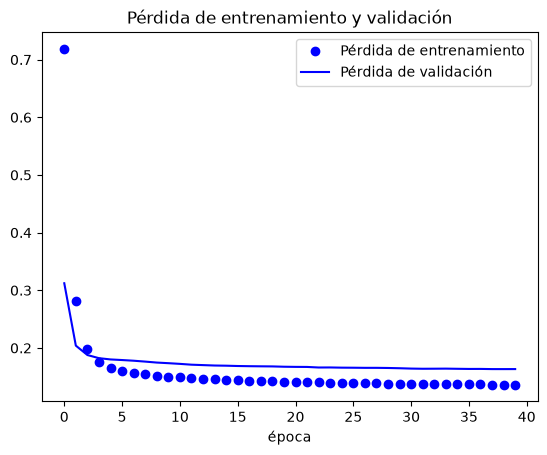

In [11]:
plt.plot(history.history['loss'], 'bo', label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], 'b', label='Pérdida de validación')
plt.title('Pérdida de entrenamiento y validación'); plt.xlabel('época'); plt.legend()
plt.savefig('grafica-perdida.png', dpi=120, bbox_inches='tight'); plt.show()

***Elegir el umbral con validación:*** el que deja al menos 85 % de precisión con el mayor número de avisos.

In [12]:
p_val = model.predict(x_val, verbose=0)[:, 0]
def medir(alarma, y):
    tp = int((alarma & (y == 1)).sum()); fp = int((alarma & (y == 0)).sum())
    return tp / max(1, (y == 1).sum()), tp / max(1, tp + fp)
UMBRAL = 0.5
for u in np.arange(0.5, 0.96, 0.05):
    rec, pre = medir(p_val > u, y_val)
    if pre >= 0.85: UMBRAL = round(float(u), 2); break
print('umbral elegido:', UMBRAL)

umbral elegido: 0.85


***Comparar contra la regla sin modelo (en prueba, datos que la red nunca vio):*** si la red no le gana a «estar cerca del límite y subiendo», no tiene sentido usarla.

In [13]:
p_test = model.predict(x_test, verbose=0)[:, 0]
filas = [('Red neuronal', p_test > UMBRAL)]
for m in (0.3, 0.5):
    filas.append((f'Regla: temp >= limite-{m} y subiendo',
                  (test.temp_menos_limite.values >= -m) & (test.subida_10min.values > 0)))
filas.append(('Regla: temp >= limite-0.3', test.temp_menos_limite.values >= -0.3))
tabla = pd.DataFrame([(n, *medir(a, y_test)) for n, a in filas], columns=['metodo', 'avisos anticipados', 'precision'])
tabla['avisos anticipados'] = (tabla['avisos anticipados'] * 100).round(0).astype(int).astype(str) + ' %'
tabla['precision'] = (tabla['precision'] * 100).round(0).astype(int).astype(str) + ' %'
print(f'{int(y_test.sum())} cruces del limite en prueba'); tabla

2844 cruces del limite en prueba


,metodo,avisos anticipados,precision
0,Red neuronal,91 %,93 %
1,Regla: temp >= limite-0.3 y subiendo,60 %,78 %
2,Regla: temp >= limite-0.5 y subiendo,72 %,45 %
3,Regla: temp >= limite-0.3,67 %,79 %


***Trazar predicciones contra lo que pasó:*** un episodio de prueba de la sala-03 con límite de 25 °C: la sala estaba vacía, entra gente, se calienta y pasa el límite.

entra gente en el minuto 0, la red avisa en el minuto 22, la sala llega a 25 C en el minuto 32


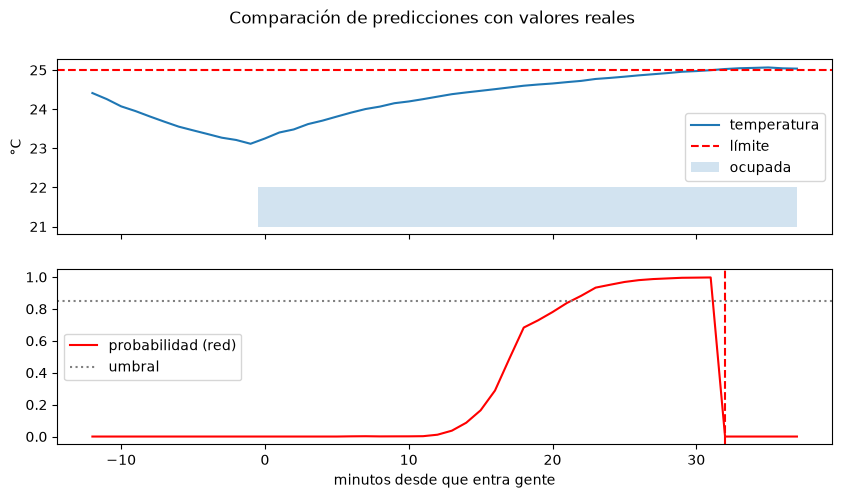

In [14]:
s3 = df[df.sala == 'sala-03'].sort_values('minuto').reset_index(drop=True)
inicio_test = int(.8 * len(s3))
t = s3.temp_c.values; o = s3.ocupada.values
# primer cruce de 25 C en prueba que empieza con la sala vacia y fria
cruce = next(i for i in range(inicio_test + 40, len(s3)) if t[i] >= 25 > t[i - 1] and t[i - 35] < 23.5 and o[i - 35] == 0)
entrada = max(i for i in range(cruce - 60, cruce) if o[i] == 1 and o[i - 1] == 0)
ep = s3.iloc[entrada - 12:cruce + 6].copy()
def entradas(win, L=25.0):
    tt, oo, rr = win.temp_c.values, win.ocupada.values, win.ruido_db.values
    filas = []
    for k in range(len(win)):
        if k < VENTANA or oo[k] == 0 or tt[k] >= L: filas.append(None); continue
        filas.append([tt[k] - L, tt[k] - tt[k - VENTANA], win.rh_pct.values[k], oo[k - VENTANA + 1:k + 1].mean(), leq(rr[k - VENTANA + 1:k + 1])])
    return filas
fil = entradas(ep)
ep['prob_keras'] = [float(model.predict(((np.array([f]) - mu) / sd).astype('float32'), verbose=0)[0, 0]) if f else 0.0 for f in fil]
ep['minuto_rel'] = np.arange(len(ep)) - 12
ep.to_csv('episodio_demo.csv', index=False)
aviso = ep[ep.prob_keras > UMBRAL].minuto_rel.min(); llega = int(ep[ep.temp_c >= 25].minuto_rel.min())
print(f'entra gente en el minuto 0, la red avisa en el minuto {aviso}, la sala llega a 25 C en el minuto {llega}')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(ep.minuto_rel, ep.temp_c, label='temperatura'); ax[0].axhline(25, color='r', ls='--', label='límite')
ax[0].fill_between(ep.minuto_rel, 21, 21 + ep.ocupada, step='mid', alpha=.2, label='ocupada'); ax[0].legend(); ax[0].set_ylabel('°C')
ax[1].plot(ep.minuto_rel, ep.prob_keras, 'r', label='probabilidad (red)'); ax[1].axhline(UMBRAL, color='gray', ls=':', label='umbral')
ax[1].axvline(llega, color='r', ls='--'); ax[1].legend(); ax[1].set_xlabel('minutos desde que entra gente')
plt.suptitle('Comparación de predicciones con valores reales')
plt.savefig('grafica-predicciones.png', dpi=120, bbox_inches='tight'); plt.show()

***Exportar los pesos de la red (forecast_weights.h) para el ESP32 en Wokwi:*** igual que `signal_weights.h`. Los kernels de Keras son (entrada, salida) y el bucle de C++ recorre (salida, entrada), por eso se transponen. Se añaden la normalización, el umbral y 8 casos de referencia para que el ESP32 compruebe al arrancar que da lo mismo que Keras.

In [15]:
w = model.get_weights()
nombres = ['NN_W1', 'NN_B1', 'NN_W2', 'NN_B2', 'NN_W3', 'NN_B3']
arr = lambda n, a: 'const float %s[%d] = {%s};\n' % (n, a.size, ', '.join('%.9ff' % v for v in a.flatten()))
out = '#ifndef FORECAST_WEIGHTS_H\n#define FORECAST_WEIGHTS_H\n\n'
out += '// Red %d-16-16-1 (Dense ReLU, Dense ReLU, Dense sigmoide) entrenada en zenroom_forecast_training.ipynb\n' % len(FEATURES)
out += '// Entradas: ' + ', '.join(FEATURES) + '\n\n'
out += '#define NN_IN %d\n#define NN_H 16\n#define NN_UMBRAL %.2ff\n#define NN_HORIZONTE_MIN %d\n#define NN_VENTANA %d\n\n' % (len(FEATURES), UMBRAL, HORIZONTE, VENTANA)
for i, (n, a) in enumerate(zip(nombres, w)):
    out += arr(n, a.T if i % 2 == 0 else a)
out += arr('NN_MU', mu.astype('float32')) + arr('NN_SD', sd.astype('float32'))
ref = pd.concat([test[test.y == 1].sample(4, random_state=1), test[test.y == 0].sample(4, random_state=1)])
out += arr('REF_X', ref[FEATURES].values.astype('float32'))
out += arr('REF_P', model.predict(norm(ref), verbose=0)[:, 0])
out += '#define REF_N 8\n\n#endif\n'
open('forecast_weights.h', 'w').write(out)
print(out[:600])

#ifndef FORECAST_WEIGHTS_H
#define FORECAST_WEIGHTS_H

// Red 5-16-16-1 (Dense ReLU, Dense ReLU, Dense sigmoide) entrenada en zenroom_forecast_training.ipynb
// Entradas: temp_menos_limite, subida_10min, humedad, ocupacion_10min, ruido_10min

#define NN_IN 5
#define NN_H 16
#define NN_UMBRAL 0.85f
#define NN_HORIZONTE_MIN 15
#define NN_VENTANA 10

const float NN_W1[80] = {0.276918232f, 0.180673480f, -0.175526157f, 0.542045712f, 0.127711177f, 0.563179255f, 0.089903809f, -0.249842912f, -0.462095648f, 0.505565226f, -0.153403118f, -0.455502599f, 0.654883504f, -0.363957912f, -0.075805806f, -0.90944


***Comprobar la exportación:*** la misma cuenta que hará el ESP32, en numpy.

In [16]:
def red_c(x):
    W1, B1, W2, B2, W3, B3 = w
    h = np.maximum(((x - mu) / sd) @ W1 + B1, 0); h = np.maximum(h @ W2 + B2, 0)
    return 1 / (1 + np.exp(-(h @ W3 + B3)[:, 0]))
print('diferencia maxima numpy vs Keras:', float(np.abs(red_c(test[FEATURES].values) - p_test).max()))

diferencia maxima numpy vs Keras: 5.308688746374912e-07
